# Customer Churn Prediction – ShopEase Retail

**Goal:** Find out which customers are likely to stop buying from ShopEase (this is called **churn**).

**Data file:** `Customer_Purchase_History.xlsx` (keep it in the same folder as this notebook)

**Steps in this notebook:**
1. Load the data
2. Look at the data
3. Clean the data (remove duplicates, fix text, fill missing values with mean / median / mode)
4. Explore the data (EDA) with simple tables and charts
5. Prepare the data for machine learning
6. Train 3 machine learning models
7. Check each model with **accuracy score** and pick the best one
8. Use the best model to predict for a new customer

## Step 1: Import the libraries

- **pandas** – to read and work with tables
- **numpy** – for simple number work
- **matplotlib** – to draw charts
- **sklearn** – for machine learning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

## Step 2: Load the data

We read the Excel file that the company gave us. It has the old purchase history of each customer.

In [2]:
df = pd.read_excel("Customer_Purchase_History.xlsx")
df.head()

,Customer_ID,Gender,Age,City,Membership_Type,Tenure_Months,Total_Orders,Total_Spend,Days_Since_Last_Purchase,Discount_Coupons_Used,Complaints_Raised,Satisfaction_Score,Payment_Method,Churn
0,C10504,Female,56.0,Bengaluru,silver,11,8,11240.0,48,13,2,2.0,Cash on Delivery,Yes
1,C11334,Male,40.0,Bengaluru,Silver,42,11,18060.0,21,10,2,3.0,Cash on Delivery,Yes
2,C12023,Female,31.0,Pune,Basic,46,13,25390.0,21,9,2,3.0,UPI,Yes
3,C11245,Male,38.0,Bengaluru,Gold,68,17,23550.0,28,11,1,3.0,UPI,No
4,C10414,Male,35.0,Mumbai,Basic,58,9,6110.0,92,3,4,1.0,Cash on Delivery,Yes


## Step 3: Look at the data

Before changing anything, we check:
- how many rows and columns there are
- the column names and their type (number or text)

In [3]:
print("Rows and columns:", df.shape)

Rows and columns: (2535, 14)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2535 entries, 0 to 2534
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer_ID               2535 non-null   str    
 1   Gender                    2535 non-null   str    
 2   Age                       2435 non-null   float64
 3   City                      2459 non-null   str    
 4   Membership_Type           2535 non-null   str    
 5   Tenure_Months             2535 non-null   int64  
 6   Total_Orders              2535 non-null   int64  
 7   Total_Spend               2409 non-null   float64
 8   Days_Since_Last_Purchase  2535 non-null   int64  
 9   Discount_Coupons_Used     2535 non-null   int64  
 10  Complaints_Raised         2535 non-null   int64  
 11  Satisfaction_Score        2433 non-null   float64
 12  Payment_Method            2458 non-null   str    
 13  Churn                     2535 non-null   str    
dtypes: float64(3), int6

## Step 4: Clean the data

Real company data is never perfect. We will fix three problems:
1. **Duplicate rows** – the same customer entered two times
2. **Messy text** – the same city written in different ways (like `delhi`, `DELHI`, ` Delhi `)
3. **Missing values** – empty cells

### 4.1 Remove duplicate rows

In [5]:
print("Duplicate rows found:", df.duplicated().sum())

Duplicate rows found: 35


In [6]:
df = df.drop_duplicates()
print("Rows after removing duplicates:", df.shape[0])

Rows after removing duplicates: 2500


### 4.2 Fix messy text

Look at the City and Membership_Type columns. The same value is written in different ways.

In [7]:
print("City values before fixing:")
print(df["City"].unique())
print()
print("Membership values before fixing:")
print(df["Membership_Type"].unique())

City values before fixing:
<StringArray>
[  'Bengaluru',        'Pune',      'Mumbai',     'Lucknow',      'Jaipur',
           nan,       'Delhi', ' Bengaluru ',      'jaipur',      'JAIPUR',
    ' Mumbai ',    ' Jaipur ',     'lucknow',      'MUMBAI',       'DELHI',
     'LUCKNOW',   'BENGALURU',       'delhi',      ' Pune ',      'mumbai',
        'PUNE',   'bengaluru',   ' Lucknow ',     ' Delhi ',        'pune']
Length: 25, dtype: str

Membership values before fixing:
<StringArray>
['silver', 'Silver', 'Basic', 'Gold', 'gold', 'basic']
Length: 6, dtype: str


We fix this in two simple steps:
- `str.strip()` removes extra spaces at the start and end
- `str.title()` makes the first letter capital and the rest small (so `DELHI` and `delhi` both become `Delhi`)

In [8]:
df["City"] = df["City"].str.strip().str.title()
df["Membership_Type"] = df["Membership_Type"].str.strip().str.title()

print("City values after fixing:")
print(df["City"].unique())
print()
print("Membership values after fixing:")
print(df["Membership_Type"].unique())

City values after fixing:
<StringArray>
['Bengaluru', 'Pune', 'Mumbai', 'Lucknow', 'Jaipur', nan, 'Delhi']
Length: 7, dtype: str

Membership values after fixing:
<StringArray>
['Silver', 'Basic', 'Gold']
Length: 3, dtype: str


### 4.3 Fill missing values

First we count the empty cells in each column.

In [9]:
df.isna().sum()

Customer_ID                   0
Gender                        0
Age                         100
City                         75
Membership_Type               0
Tenure_Months                 0
Total_Orders                  0
Total_Spend                 125
Days_Since_Last_Purchase      0
Discount_Coupons_Used         0
Complaints_Raised             0
Satisfaction_Score          100
Payment_Method               75
Churn                         0
dtype: int64

We fill empty cells with **only three simple methods**:

| Method | What it means | When we use it |
|---|---|---|
| **Mean** | The average value | For number columns where values are spread evenly, like Age |
| **Median** | The middle value when all values are put in order | For money columns, because a few very big spenders can pull the average up |
| **Mode** | The value that appears the most | For text columns (City, Payment Method) and for ratings (Satisfaction Score) |

**Age → Mean.** Age values are spread evenly, so the average age is a fair guess. We round it to a whole number because age is a whole number.

In [10]:
age_mean = round(df["Age"].mean())
print("Mean age:", age_mean)

df["Age"] = df["Age"].fillna(age_mean)
df["Age"] = df["Age"].astype(int)

Mean age: 36


**Total_Spend → Median.** A few customers spend a very large amount. These big numbers pull the average up, so the average is not a fair guess for a normal customer. The middle value (median) is safer.

In [11]:
print("Mean spend  :", round(df["Total_Spend"].mean()))
print("Median spend:", round(df["Total_Spend"].median()))

spend_median = df["Total_Spend"].median()
df["Total_Spend"] = df["Total_Spend"].fillna(spend_median)

Mean spend  : 17588
Median spend: 14140


**City, Payment_Method → Mode.** We cannot take the average of text. So we use the most common value.

**Satisfaction_Score → Mode.** This is a rating from 1 to 5. A rating like 3.7 does not exist, so we use the most common rating.

In [12]:
city_mode = df["City"].mode()[0]
payment_mode = df["Payment_Method"].mode()[0]
score_mode = df["Satisfaction_Score"].mode()[0]

print("Most common city          :", city_mode)
print("Most common payment method:", payment_mode)
print("Most common rating        :", score_mode)

df["City"] = df["City"].fillna(city_mode)
df["Payment_Method"] = df["Payment_Method"].fillna(payment_mode)
df["Satisfaction_Score"] = df["Satisfaction_Score"].fillna(score_mode)
df["Satisfaction_Score"] = df["Satisfaction_Score"].astype(int)

Most common city          : Delhi
Most common payment method: UPI
Most common rating        : 4.0


Now we check again. Every column should show **0** missing values.

In [13]:
df.isna().sum()

Customer_ID                 0
Gender                      0
Age                         0
City                        0
Membership_Type             0
Tenure_Months               0
Total_Orders                0
Total_Spend                 0
Days_Since_Last_Purchase    0
Discount_Coupons_Used       0
Complaints_Raised           0
Satisfaction_Score          0
Payment_Method              0
Churn                       0
dtype: int64

In [14]:
print("Clean data shape:", df.shape)
df.head()

Clean data shape: (2500, 14)


,Customer_ID,Gender,Age,City,Membership_Type,Tenure_Months,Total_Orders,Total_Spend,Days_Since_Last_Purchase,Discount_Coupons_Used,Complaints_Raised,Satisfaction_Score,Payment_Method,Churn
0,C10504,Female,56,Bengaluru,Silver,11,8,11240.0,48,13,2,2,Cash on Delivery,Yes
1,C11334,Male,40,Bengaluru,Silver,42,11,18060.0,21,10,2,3,Cash on Delivery,Yes
2,C12023,Female,31,Pune,Basic,46,13,25390.0,21,9,2,3,UPI,Yes
3,C11245,Male,38,Bengaluru,Gold,68,17,23550.0,28,11,1,3,UPI,No
4,C10414,Male,35,Mumbai,Basic,58,9,6110.0,92,3,4,1,Cash on Delivery,Yes


## Step 5: Explore the data (EDA)

EDA means **looking at the data to understand it** before building a model.
We ask simple business questions and answer them with tables and charts.

To make counting easy, we add a helper column: **Churn_Flag** = 1 if the customer left, 0 if the customer stayed.

In [15]:
df["Churn_Flag"] = np.where(df["Churn"] == "Yes", 1, 0)

### 5.1 Summary of number columns

In [16]:
df.describe().round(1)

,Age,Tenure_Months,Total_Orders,Total_Spend,Days_Since_Last_Purchase,Discount_Coupons_Used,Complaints_Raised,Satisfaction_Score,Churn_Flag
count,2500.0,2500.0,2500.0,2500.0,2500.0,2500.0,2500.0,2500.0,2500.0
mean,35.9,36.2,12.1,17415.3,44.4,6.8,1.1,3.7,0.3
std,9.3,21.0,5.2,12294.1,43.9,4.3,1.4,1.0,0.5
min,18.0,1.0,1.0,270.0,1.0,0.0,0.0,1.0,0.0
25%,30.0,18.0,8.0,8700.0,13.0,3.0,0.0,3.0,0.0
50%,36.0,36.0,11.0,14140.0,31.0,7.0,1.0,4.0,0.0
75%,42.0,54.0,15.0,23132.5,62.0,10.0,2.0,4.0,1.0
max,65.0,72.0,34.0,89370.0,365.0,14.0,5.0,5.0,1.0


### 5.2 How many customers left?

In [17]:
print(df["Churn"].value_counts())
print()
print("Percentage of customers who left:", round(df["Churn_Flag"].mean() * 100, 1), "%")

Churn
No     1750
Yes     750
Name: count, dtype: int64

Percentage of customers who left: 30.0 %


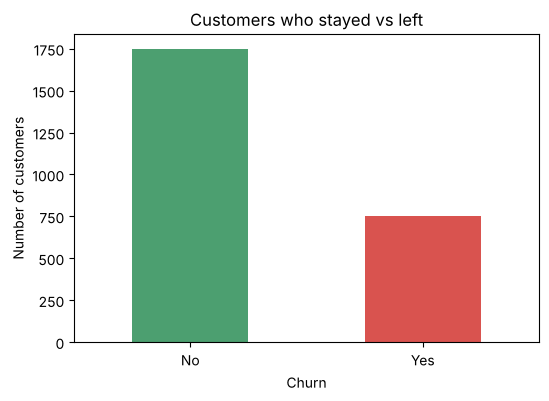

In [18]:
df["Churn"].value_counts().plot(kind="bar", color=["#4C9F70", "#D9534F"], figsize=(6, 4))
plt.title("Customers who stayed vs left")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.xticks(rotation=0)
plt.show()

### 5.3 Does membership type matter?

We find the **churn % for each membership type** (out of 100 customers in that group, how many left).

In [19]:
churn_by_membership = (df.groupby("Membership_Type")["Churn_Flag"].mean() * 100).round(1)
churn_by_membership = churn_by_membership.sort_values(ascending=False)
churn_by_membership

Membership_Type
Basic     37.3
Silver    26.0
Gold      17.7
Name: Churn_Flag, dtype: float64

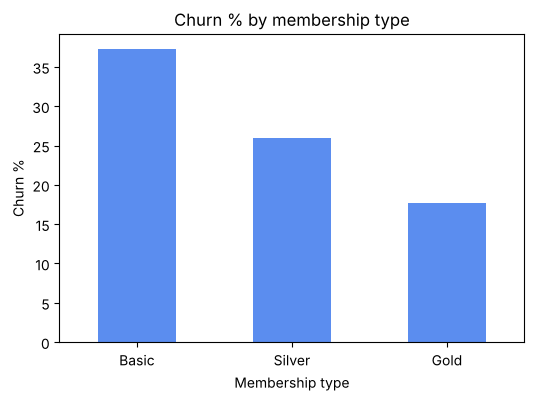

In [20]:
churn_by_membership.plot(kind="bar", color="#5B8DEF", figsize=(6, 4))
plt.title("Churn % by membership type")
plt.xlabel("Membership type")
plt.ylabel("Churn %")
plt.xticks(rotation=0)
plt.show()

### 5.4 Do complaints make customers leave?

In [21]:
churn_by_complaints = (df.groupby("Complaints_Raised")["Churn_Flag"].mean() * 100).round(1)
churn_by_complaints

Complaints_Raised
0    16.8
1    26.8
2    37.3
3    56.6
4    66.4
5    76.7
Name: Churn_Flag, dtype: float64

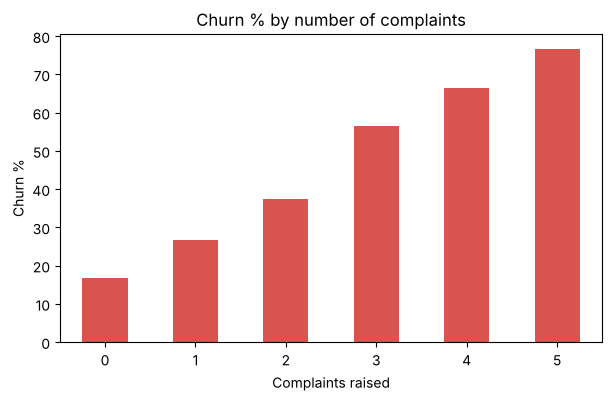

In [22]:
churn_by_complaints.plot(kind="bar", color="#D9534F", figsize=(7, 4))
plt.title("Churn % by number of complaints")
plt.xlabel("Complaints raised")
plt.ylabel("Churn %")
plt.xticks(rotation=0)
plt.show()

### 5.5 Does the satisfaction score matter?

In [23]:
churn_by_score = (df.groupby("Satisfaction_Score")["Churn_Flag"].mean() * 100).round(1)
churn_by_score

Satisfaction_Score
1    70.2
2    63.1
3    36.6
4    22.9
5    14.2
Name: Churn_Flag, dtype: float64

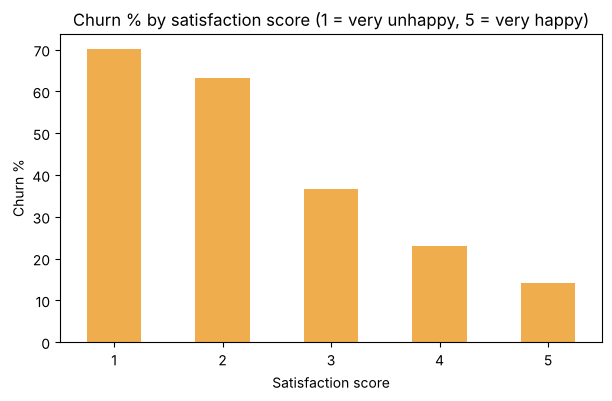

In [24]:
churn_by_score.plot(kind="bar", color="#F0AD4E", figsize=(7, 4))
plt.title("Churn % by satisfaction score (1 = very unhappy, 5 = very happy)")
plt.xlabel("Satisfaction score")
plt.ylabel("Churn %")
plt.xticks(rotation=0)
plt.show()

### 5.6 Customers who left vs customers who stayed

We compare the **average** of some important columns for both groups.

In [25]:
compare_cols = ["Tenure_Months", "Total_Orders", "Total_Spend", "Days_Since_Last_Purchase", "Complaints_Raised"]
df.groupby("Churn")[compare_cols].mean().round(1)

,Tenure_Months,Total_Orders,Total_Spend,Days_Since_Last_Purchase,Complaints_Raised
Churn,,,,,
No,38.6,12.7,18681.4,31.6,0.8
Yes,30.4,10.4,14461.0,74.3,1.9


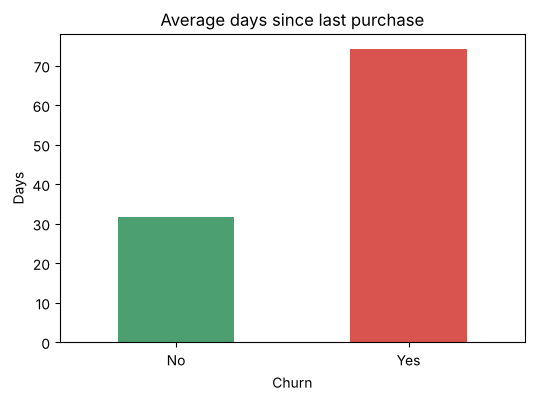

In [26]:
df.groupby("Churn")["Days_Since_Last_Purchase"].mean().plot(kind="bar", color=["#4C9F70", "#D9534F"], figsize=(6, 4))
plt.title("Average days since last purchase")
plt.xlabel("Churn")
plt.ylabel("Days")
plt.xticks(rotation=0)
plt.show()

### 5.7 Does payment method or city matter?

In [27]:
churn_by_payment = (df.groupby("Payment_Method")["Churn_Flag"].mean() * 100).round(1).sort_values(ascending=False)
churn_by_payment

Payment_Method
Cash on Delivery     36.9
Debit/Credit Card    30.9
UPI                  27.7
Wallet               25.2
Name: Churn_Flag, dtype: float64

In [28]:
churn_by_city = (df.groupby("City")["Churn_Flag"].mean() * 100).round(1).sort_values(ascending=False)
churn_by_city

City
Bengaluru    32.2
Pune         31.3
Jaipur       30.8
Lucknow      30.0
Delhi        29.7
Mumbai       27.1
Name: Churn_Flag, dtype: float64

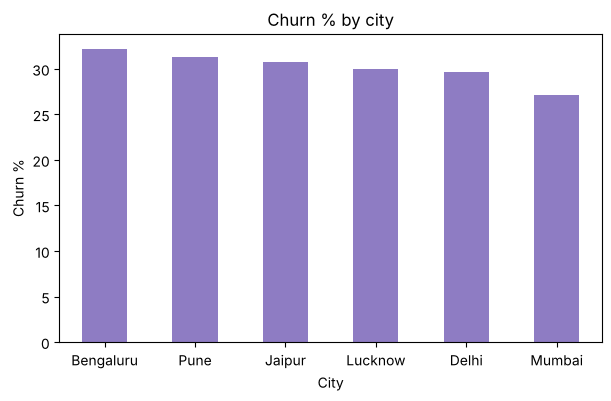

In [29]:
churn_by_city.plot(kind="bar", color="#8E7CC3", figsize=(7, 4))
plt.title("Churn % by city")
plt.xlabel("City")
plt.ylabel("Churn %")
plt.xticks(rotation=0)
plt.show()

### What we learned from EDA

1. **30% of customers left** (750 out of 2,500). This is a big number for the company.
2. **Membership matters.** Basic members leave the most (37.3%). Gold members leave the least (17.7%).
3. **Complaints are a strong warning sign.** Customers with no complaints left only 16.8% of the time. Customers with 5 complaints left 76.7% of the time.
4. **Unhappy customers leave.** Customers who gave a score of 1 left 70.2% of the time. Customers who gave 5 left only 14.2% of the time.
5. **Long gap since last purchase = danger.** Customers who left had not bought anything for 74 days on average. Customers who stayed had bought something in the last 32 days on average.
6. **Newer customers leave more.** Customers who left had been with the company for about 30 months. Customers who stayed had been with the company for about 39 months, and they also placed more orders.
7. **Cash on Delivery customers leave more** (36.9%) than Wallet users (25.2%).
8. **City does not matter much.** Churn is between 27% and 32% in every city.

## Step 6: Prepare the data for machine learning

A machine learning model understands **only numbers**. So we:
1. Remove **Customer_ID** – it is just a name tag and does not tell us anything about the customer's behaviour
2. Remove the text **Churn** column – we already have Churn_Flag (1 or 0), which is our answer column
3. Turn text columns into number columns using `pd.get_dummies()`

In [30]:
data = df.drop(columns=["Customer_ID", "Churn"])

**What does `get_dummies` do?**

It turns one text column into several 0/1 columns. For example, the `Membership_Type` column becomes:

| Membership_Type_Basic | Membership_Type_Gold | Membership_Type_Silver |
|---|---|---|
| 1 | 0 | 0 |
| 0 | 1 | 0 |

So a Gold member gets 1 in the Gold column and 0 in the others.

In [31]:
text_cols = ["Gender", "City", "Membership_Type", "Payment_Method"]
data = pd.get_dummies(data, columns=text_cols, dtype=int)
data.head()

,Age,Tenure_Months,Total_Orders,Total_Spend,Days_Since_Last_Purchase,Discount_Coupons_Used,Complaints_Raised,Satisfaction_Score,Churn_Flag,Gender_Female,...,City_Lucknow,City_Mumbai,City_Pune,Membership_Type_Basic,Membership_Type_Gold,Membership_Type_Silver,Payment_Method_Cash on Delivery,Payment_Method_Debit/Credit Card,Payment_Method_UPI,Payment_Method_Wallet
0,56,11,8,11240.0,48,13,2,2,1,1,...,0,0,0,0,0,1,1,0,0,0
1,40,42,11,18060.0,21,10,2,3,1,0,...,0,0,0,0,0,1,1,0,0,0
2,31,46,13,25390.0,21,9,2,3,1,1,...,0,0,1,1,0,0,0,0,1,0
3,38,68,17,23550.0,28,11,1,3,0,0,...,0,0,0,0,1,0,0,0,1,0
4,35,58,9,6110.0,92,3,4,1,1,0,...,0,1,0,1,0,0,1,0,0,0


Now we split the table into two parts:
- **X** = the input columns (everything we know about the customer)
- **y** = the answer column (Churn_Flag: did the customer leave?)

In [32]:
X = data.drop(columns=["Churn_Flag"])
y = data["Churn_Flag"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2500, 23)
y shape: (2500,)


### Train and test split

We keep **80%** of the customers to **teach** the model (train data) and hide **20%** to **test** the model later (test data).
This is like a student who practises on some questions and then takes an exam on new questions.

`random_state=42` makes sure we get the same split every time we run the notebook.

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train rows:", X_train.shape[0])
print("Test rows :", X_test.shape[0])

Train rows: 2000
Test rows : 500


## Step 7: Train the models and check accuracy

We try **3 simple models** and compare them:

1. **Logistic Regression** – a simple model that gives a Yes/No answer
2. **Decision Tree** – asks a chain of yes/no questions, like a flowchart
3. **Random Forest** – builds many decision trees and takes the majority vote

**Accuracy score** = out of all test customers, how many did the model predict correctly.
For example, 0.85 means the model was right for 85 out of 100 customers.

### Model 1: Logistic Regression

In [34]:
log_model = LogisticRegression(max_iter=5000)
log_model.fit(X_train, y_train)

log_pred = log_model.predict(X_test)
log_acc = accuracy_score(y_test, log_pred)
print("Logistic Regression accuracy:", round(log_acc, 3))

Logistic Regression accuracy: 0.852


### Model 2: Decision Tree

In [35]:
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)
tree_acc = accuracy_score(y_test, tree_pred)
print("Decision Tree accuracy:", round(tree_acc, 3))

Decision Tree accuracy: 0.73


### Model 3: Random Forest

In [36]:
forest_model = RandomForestClassifier(random_state=42)
forest_model.fit(X_train, y_train)

forest_pred = forest_model.predict(X_test)
forest_acc = accuracy_score(y_test, forest_pred)
print("Random Forest accuracy:", round(forest_acc, 3))

Random Forest accuracy: 0.838


### Compare the three models

In [37]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Accuracy": [log_acc, tree_acc, forest_acc]
})
results["Accuracy %"] = (results["Accuracy"] * 100).round(1)
results = results.sort_values("Accuracy", ascending=False)
results

,Model,Accuracy,Accuracy %
0,Logistic Regression,0.852,85.2
2,Random Forest,0.838,83.8
1,Decision Tree,0.730,73.0


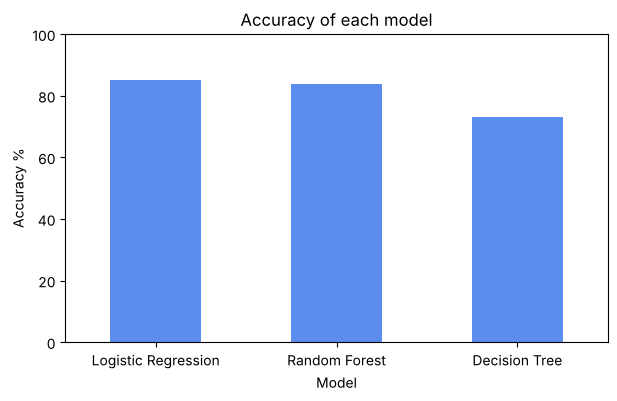

In [38]:
results.plot(x="Model", y="Accuracy %", kind="bar", legend=False, color="#5B8DEF", figsize=(7, 4))
plt.title("Accuracy of each model")
plt.ylabel("Accuracy %")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()

**Is this accuracy good?** If we simply said "No, nobody will leave" for every customer, we would be right only as often as customers actually stay.
Let us check that number, so we know the model is really learning something.

In [39]:
stay_percent = round((y_test == 0).mean() * 100, 1)
print("If we guess 'No churn' for everyone, we are right", stay_percent, "% of the time.")
print("Our best model is right", results["Accuracy %"].iloc[0], "% of the time.")

If we guess 'No churn' for everyone, we are right 70.4 % of the time.
Our best model is right 85.2 % of the time.


### Which model is the best?

| Model | Accuracy |
|---|---|
| Logistic Regression | **85.2%** |
| Random Forest | 83.8% |
| Decision Tree | 73.0% |

**Logistic Regression is the best model.** It predicted correctly for about 85 out of 100 customers it had never seen before.

If we just guessed "No churn" for everyone, we would be right only 70.4% of the time. So the model is clearly learning real patterns from the data.

**Why is the Decision Tree the weakest?** A single tree learns the training data too closely, almost like memorising answers. So it makes more mistakes on new customers. Random Forest fixes this partly because many trees vote together.

We will use **Logistic Regression** for the next steps.

## Step 8: Check some predictions

Let us look at 10 test customers: what really happened vs what the model said.

In [40]:
check = pd.DataFrame({
    "Actual": y_test.values[:10],
    "Predicted": log_pred[:10]
})
check["Actual"] = check["Actual"].map({1: "Left", 0: "Stayed"})
check["Predicted"] = check["Predicted"].map({1: "Left", 0: "Stayed"})
check["Correct?"] = np.where(check["Actual"] == check["Predicted"], "Yes", "No")
check

,Actual,Predicted,Correct?
0,Left,Left,Yes
1,Stayed,Stayed,Yes
2,Left,Stayed,No
3,Stayed,Stayed,Yes
4,Left,Stayed,No
5,Stayed,Stayed,Yes
6,Left,Left,Yes
7,Stayed,Stayed,Yes
8,Stayed,Stayed,Yes
9,Stayed,Stayed,Yes


## Step 9: Predict for a new customer

This is how the company will use the model every day. We give details of one customer and the model tells us if this customer is likely to leave.

We must turn the new customer's text values into 0/1 columns in the same way, and make sure the columns are in the same order as X. `reindex` does this and fills any missing column with 0.

In [41]:
new_customer = pd.DataFrame({
    "Gender": ["Female"],
    "Age": [29],
    "City": ["Pune"],
    "Membership_Type": ["Basic"],
    "Tenure_Months": [5],
    "Total_Orders": [4],
    "Total_Spend": [3800],
    "Days_Since_Last_Purchase": [120],
    "Discount_Coupons_Used": [2],
    "Complaints_Raised": [3],
    "Satisfaction_Score": [2],
    "Payment_Method": ["Cash on Delivery"]
})

new_data = pd.get_dummies(new_customer, columns=text_cols, dtype=int)
new_data = new_data.reindex(columns=X.columns, fill_value=0)

answer = log_model.predict(new_data)[0]
if answer == 1:
    print("This customer is LIKELY TO LEAVE. The team should contact them with an offer.")
else:
    print("This customer is likely to STAY.")

This customer is LIKELY TO LEAVE. The team should contact them with an offer.


## Conclusion

- We cleaned the company's old data: removed 35 duplicate rows, fixed messy city and membership names, and filled missing values using only mean, median and mode.
- EDA showed the main warning signs of churn: **a long gap since the last purchase, many complaints, a low satisfaction score, Basic membership, and Cash on Delivery payment.**
- We trained 3 models. **Logistic Regression gave the best accuracy (85.2%).**
- In the sample of 10 test customers, the model was right for 8. It is not perfect, so it should help the team decide, not replace the team.

**How the company can use this:** Every month, run the model on all current customers. Give the list of customers who are likely to leave to the customer care team, so they can call them, solve their complaints and offer them a discount or a membership upgrade.